In [1]:
import re
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio
from tqdm.auto import tqdm

In [2]:
DATA_ROOT = Path.cwd()
OUTPUT_ROOT = DATA_ROOT / "parquet"
OUTPUT_ROOT.mkdir(exist_ok=True)
TEST_DIR = DATA_ROOT / "test"

In [3]:
OPTUNA_N_TRIALS = 15

In [4]:
FILENAME_RE = re.compile(
    r"^(?P<speed_code>N\d{2})_(?P<load_code>M\d{2})_(?P<force_code>F\d{2})_"
    r"(?P<bearing_code>[A-Z]{1,2}\d{2,3})_(?P<run>\d+)$"
)

SPEED_RPM = {"N09": 900, "N15": 1500}
LOAD_TORQUE_NM = {"M07": 0.7, "M01": 0.1}
RADIAL_FORCE_N = {"F10": 1000, "F04": 400}

In [5]:
# TARGET_MAPPING = {
#     **{code: "healthy" for code in ["K001", "K002", "K003", "K004", "K005", "K006"]},
#     **{
#         code: "artificial_damage_outer_ring"
#         for code in ["KA01", "KA03", "KA05", "KA06", "KA07", "KA08", "KA09"]
#     },
#     **{
#         code: "artificial_damage_inner_ring"
#         for code in ["KI01", "KI03", "KI05", "KI07", "KI08"]
#     },
#     **{
#         code: "real_damage_outer_ring"
#         for code in ["KA04", "KA15", "KA16", "KA22", "KA30"]
#     },
#     **{
#         code: "real_damage_inner_ring"
#         for code in ["KI04", "KI14", "KI16", "KI17", "KI18", "KI21"]
#     },
#     **{code: "real_damage_both_rings" for code in ["KB23", "KB24", "KB27"]},
# }

In [6]:
TARGET_MAPPING = {
    **{code: "healthy" for code in ["K001", "K002", "K003", "K004", "K005", "K006"]},
    **{
        code: "artificial_damage"
        for code in ["KA01", "KA03", "KA05", "KA06", "KA07", "KA08", "KA09", "KI01", "KI03", "KI05", "KI07", "KI08"]
    },
    **{
        code: "real_damage"
        for code in ["KA04", "KA15", "KA16", "KA22", "KA30", "KI04", "KI14", "KI16", "KI17", "KI18", "KI21", "KB23", "KB24", "KB27"]
    }
}

In [7]:
def bearing_condition(bearing_code: str) -> str:
    return TARGET_MAPPING[bearing_code]


def parse_filename(stem: str) -> dict:
    m = FILENAME_RE.match(stem)
    if not m:
        raise ValueError(f"Filename does not match the expected pattern: {stem!r}")
    g = m.groupdict()
    for code, table, label in (
        (g["speed_code"], SPEED_RPM, "speed_code"),
        (g["load_code"], LOAD_TORQUE_NM, "load_code"),
        (g["force_code"], RADIAL_FORCE_N, "force_code"),
    ):
        if code not in table:
            raise ValueError(f"Unknown {label} {code!r} in {stem!r}")
    return {
        "file_stem": stem,
        "speed_rpm": SPEED_RPM[g["speed_code"]],
        "load_torque_nm": LOAD_TORQUE_NM[g["load_code"]],
        "radial_force_n": RADIAL_FORCE_N[g["force_code"]],
        "bearing_code": g["bearing_code"],
        "bearing_condition": bearing_condition(g["bearing_code"]),
        "run": int(g["run"]),
    }

In [8]:
def _slug(raster: str) -> str:
    return re.sub(r"[^a-z0-9]+", "_", raster.lower()).strip("_")


def load_mat_file(path: Path) -> tuple[dict[str, pd.DataFrame], dict]:
    """Load one Paderborn .mat measurement into {raster_name: DataFrame} + metadata."""
    raw = sio.loadmat(path, struct_as_record=False, squeeze_me=True)
    key = next(k for k in raw if not k.startswith("__"))
    top = raw[key]

    time_by_raster = {
        x.Raster: np.asarray(x.Data, dtype=float) for x in np.atleast_1d(top.X)
    }

    channels_by_raster: dict[str, dict[str, np.ndarray]] = {}
    for ch in np.atleast_1d(top.Y):
        channels_by_raster.setdefault(ch.Raster, {})[ch.Name] = np.asarray(
            ch.Data, dtype=float
        )

    frames = {}
    for raster, channels in channels_by_raster.items():
        df = pd.DataFrame(channels)
        time = time_by_raster.get(raster)
        if time is not None and len(time) == len(df):
            df.insert(0, "time_s", time)
        frames[raster] = df

    metadata = {
        "measurement_id": int(top.Info.MeasurementID),
        "recording_datetime": datetime.strptime(
            str(top.Description.General.DateTime), "%d.%m.%Y %H:%M:%S"
        ),
        "measurement_length_s": float(top.Description.Measurement.Length),
    }
    return frames, metadata

In [9]:
_sample_path = DATA_ROOT / "K001" / "N09_M07_F10_K001_1.mat"
_frames, _meta = load_mat_file(_sample_path)

print(_meta)
for raster, df in _frames.items():
    print(raster, df.shape, list(df.columns))
_frames["HostService"].head()

{'measurement_id': 22, 'recording_datetime': datetime.datetime(2015, 9, 17, 19, 51, 22), 'measurement_length_s': 4.0}
Mech_4kHz (16008, 4) ['time_s', 'force', 'speed', 'torque']
HostService (256823, 4) ['time_s', 'phase_current_1', 'phase_current_2', 'vibration_1']
Temp_1Hz (5, 2) ['time_s', 'temp_2_bearing_module']


,time_s,phase_current_1,phase_current_2,vibration_1
0,-0.000003,-0.872686,-1.146133,0.064087
1,0.000012,-0.945697,-1.245317,-0.122070
2,0.000028,-1.037994,-1.368609,0.112915
3,0.000043,-0.922279,-1.321083,0.384521
4,0.000059,-0.823094,-1.188148,0.079346


In [10]:
def convert_and_save(mat_path: Path, output_root: Path) -> dict:
    """Convert one .mat file to per-raster Parquet files and return a catalog row."""
    mat_path = Path(mat_path)
    meta = parse_filename(mat_path.stem)
    frames, mat_meta = load_mat_file(mat_path)

    bearing_dir = output_root / meta["bearing_code"]
    bearing_dir.mkdir(parents=True, exist_ok=True)

    row = {**meta, **mat_meta, "source_file": str(mat_path)}
    for raster, df in frames.items():
        slug = _slug(raster)
        out_path = bearing_dir / f"{mat_path.stem}__{slug}.parquet"
        df.to_parquet(out_path, index=False)
        row[f"n_samples_{slug}"] = len(df)
        row[f"path_{slug}"] = str(out_path.relative_to(output_root))
    return row


def discover_mat_files(data_root: Path) -> list[Path]:
    return sorted(data_root.glob("K*/*.mat"))


def build_catalog(mat_files: list[Path], output_root: Path) -> pd.DataFrame:
    rows, errors = [], []
    for f in tqdm(mat_files):
        try:
            rows.append(convert_and_save(f, output_root))
        except Exception as exc:
            errors.append((str(f), repr(exc)))
    if errors:
        print(f"{len(errors)} file(s) failed:")
        for f, e in errors:
            print(" ", f, "->", e)
    return pd.DataFrame(rows)

Читаем директории и конвертируем .mat в .parquet


In [11]:
all_mat_files = discover_mat_files(DATA_ROOT)

In [12]:
catalog = build_catalog(all_mat_files, OUTPUT_ROOT)
catalog.to_parquet(OUTPUT_ROOT / "catalog.parquet", index=False)
catalog.to_csv(OUTPUT_ROOT / "catalog.csv", index=False)

  0%|          | 0/1920 [00:00<?, ?it/s]

In [13]:
catalog.head()

,file_stem,speed_rpm,load_torque_nm,radial_force_n,bearing_code,bearing_condition,run,measurement_id,recording_datetime,measurement_length_s,source_file,n_samples_mech_4khz,path_mech_4khz,n_samples_hostservice,path_hostservice,n_samples_temp_1hz,path_temp_1hz
0,N09_M07_F10_K001_1,900,0.7,1000,K001,healthy,1,22,2015-09-17 19:51:22,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16008,K001\N09_M07_F10_K001_1__mech_4khz.parquet,256823,K001\N09_M07_F10_K001_1__hostservice.parquet,5,K001\N09_M07_F10_K001_1__temp_1hz.parquet
1,N09_M07_F10_K001_10,900,0.7,1000,K001,healthy,10,31,2015-09-17 20:00:03,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16007,K001\N09_M07_F10_K001_10__mech_4khz.parquet,256608,K001\N09_M07_F10_K001_10__hostservice.parquet,5,K001\N09_M07_F10_K001_10__temp_1hz.parquet
2,N09_M07_F10_K001_11,900,0.7,1000,K001,healthy,11,32,2015-09-17 20:00:37,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16007,K001\N09_M07_F10_K001_11__mech_4khz.parquet,256096,K001\N09_M07_F10_K001_11__hostservice.parquet,5,K001\N09_M07_F10_K001_11__temp_1hz.parquet
3,N09_M07_F10_K001_12,900,0.7,1000,K001,healthy,12,33,2015-09-17 20:01:10,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16001,K001\N09_M07_F10_K001_12__mech_4khz.parquet,256000,K001\N09_M07_F10_K001_12__hostservice.parquet,5,K001\N09_M07_F10_K001_12__temp_1hz.parquet
4,N09_M07_F10_K001_13,900,0.7,1000,K001,healthy,13,34,2015-09-17 20:01:41,4.0,D:\Almaz\ML_Ваттметрирование\Datasets\K001\N09...,16001,K001\N09_M07_F10_K001_13__mech_4khz.parquet,256000,K001\N09_M07_F10_K001_13__hostservice.parquet,5,K001\N09_M07_F10_K001_13__temp_1hz.parquet


In [14]:
BALL_PARAMS = dict(d_ball=6.75, d_pitch=28.55, n_balls=8, phi=0, pole_pairs=4)
FS = 64000.0
HARMONICS = [1, 2, 3]
# TARGET_NAME_TO_CODE = {
#     "healthy": 0,
#     "artificial_damage_outer_ring": 1,
#     "real_damage_outer_ring": 2,
#     "real_damage_both_rings": 3,
#     "artificial_damage_inner_ring": 4,
#     "real_damage_inner_ring": 5,
# }
TARGET_NAME_TO_CODE = {
    "healthy": 0,
    "artificial_damage": 1,
    "real_damage": 2,
}
# N_CLASSES = 6
N_CLASSES = 3

In [15]:
def bearing_freqs():
    r = BALL_PARAMS["d_ball"] / BALL_PARAMS["d_pitch"] * np.cos(BALL_PARAMS["phi"])
    n = BALL_PARAMS["n_balls"]
    return {
        "BPFO": n / 2 * (1 - r),
        "BPFI": n / 2 * (1 + r),
        "BSF": BALL_PARAMS["d_pitch"] / (2 * BALL_PARAMS["d_ball"]) * (1 - r**2),
        "FTF": 0.5 * (1 - r),
    }

In [16]:
import scipy
import polars as pl

In [17]:
def fourier_transform_vibration(frame: pd.Series, fs: float):
    """Преобразование Фурье для сигналов вибрации"""
    x = frame.to_numpy()
    ny = fs / 2
    band = [2000, ny * 0.95]

    sos = scipy.signal.butter(4, band, btype="bandpass", fs=fs, output="sos")
    x_filt = scipy.signal.sosfiltfilt(sos, (x - x.mean()))
    env = np.abs(scipy.signal.hilbert(x_filt))
    env -= env.mean()

    window = scipy.signal.windows.hann(len(env))
    fft_values = scipy.fft.rfft(env * window)
    freqs = scipy.fft.rfftfreq(len(env), 1 / fs)
    amps = np.abs(fft_values) * 2 / np.sum(window)
    return dict(frequences=freqs, amplitudes=amps)

In [18]:
def fourier_transform_current(frame: pd.Series, fs: float):
    """Преобразование Фурье для сигналов тока"""
    x = frame.to_numpy()

    window = scipy.signal.windows.hann(len(x))
    fft_values = scipy.fft.rfft((x - x.mean()) * window)
    freqs = scipy.fft.rfftfreq(len(x), 1 / fs)
    amps = np.abs(fft_values) * 2 / np.sum(window)
    return dict(frequences=freqs, amplitudes=amps)

In [19]:
def peak_amplitude(freqs, amps, f0, tol):
    if f0 <= 0 or f0 >= freqs[-1]:
        return 0.0
    mask = (freqs >= f0 - tol) & (freqs <= f0 + tol)
    return amps[mask].max()

In [20]:
def prepare_time_features(frame: pd.DataFrame, agg_cols: list[str]):
    N = frame.shape[0] // 4
    features = {}
    time_df = pd.DataFrame(index=frame.index)
    for col in agg_cols:
        time_df[f"{col}_kurtosis"] = frame[f"{col}"].rolling(N).kurt()
        time_df[f"{col}_mean"] = frame[f"{col}"].rolling(N).mean()
        time_df[f"{col}_min"] = frame[f"{col}"].rolling(N).min()
        time_df[f"{col}_max"] = frame[f"{col}"].rolling(N).max()
        time_df[f"{col}_std"] = frame[f"{col}"].rolling(N).std()
        time_df[f"{col}_skew"] = frame[f"{col}"].rolling(N).skew()

    time_df = time_df.dropna()
    values_per_second = time_df.iloc[::N].iloc[1:]
    for col in time_df.columns:
        for t, val in enumerate(values_per_second[col]):
            features[f"{col}__t{(t+1)}"] = val

    return features

Итеративно обрабатываем метадатасет и применяем преобразования...


In [21]:
import pywt


def prepare_wpd_features(
    df: pd.DataFrame, prefix: str, level: int = 3, wavelet: str = "db4"
) -> dict:
    x = df[prefix].to_numpy()
    """Нормированные энергии вейвлет-пакетного разложения"""

    wp = pywt.WaveletPacket(data=x, wavelet=wavelet, mode="symmetric", maxlevel=level)
    nodes = [n.path for n in wp.get_level(level, "natural")]
    e = np.array([np.sum(wp[p].data ** 2) for p in nodes], dtype=np.float64)
    e = e / (e.sum() + 1e-20)
    return {f"{prefix}_wpd{i}": float(v) for i, v in enumerate(e)}

In [22]:
def welch_psd(x: np.ndarray, fs: float, nperseg: int = 4096):
    f, p = scipy.signal.welch(x, fs=fs, nperseg=min(nperseg, len(x)), scaling="density")
    return f, p + 1e-20


def prepare_spectral_features(df: pd.DataFrame, fs: float, prefix: str, n_bands: int = 10) -> dict:
    """Логарифмические энергии в полосах"""
    x = df[prefix].to_numpy()
    f, p = welch_psd(x, fs)
    pn = p / p.sum()
    out = {
        f"{prefix}_sp_centroid": float((f * pn).sum()),
        f"{prefix}_sp_spread": float(np.sqrt((((f - (f * pn).sum()) ** 2) * pn).sum())),
        f"{prefix}_sp_entropy": float(-(pn * np.log(pn)).sum() / np.log(len(pn))),
    }

    # лог. сетка от 10 Гц до частоты Найквиста
    edges = np.logspace(np.log10(10.0), np.log10(fs / 2), n_bands + 1)
    for i in range(n_bands):
        m = (f >= edges[i]) & (f < edges[i + 1])
        out[f"{prefix}_band{i}"] = (
            float(np.log10(p[m].sum() + 1e-20)) if m.any() else -20.0
        )
    return out

In [23]:
def prepare_feature_spectrum(df: pd.DataFrame, prefix: str, rpm: int):
    """
    Готовим спектральные признаки по каждой заданной в словаре частоте.
    - prefix - имя колонки, ток или вибрация
    - bearing_features - словарь с нужными частотами, на которых ищем аномалии, причем базовая частота идет как скорость вращения вала / 60
    - harmonics - нужная нам гармоника
    - rpm - частота вращения
    - f_e - частота питания
    - fr - частота вращения / 60
    - tol - допущение, в пределах которого искомая частота
    - f0 - коэффициент нужной частоты (bpfi, bpfo, ftf, bsf)
    """
    fr = rpm / 60
    features = {}
    bearing_features = bearing_freqs().items()
    if prefix.startswith("vibration"):
        # вибрация
        fourier_signal = fourier_transform_vibration(df[prefix], FS)
        freqs = fourier_signal["frequences"]
        amps = fourier_signal["amplitudes"]

        floor = np.median(amps[(freqs > 5) & (freqs < 1000)]) + 1e-12
        tol = max(2.0, 3 * (freqs[1] - freqs[0]))

        # гармоники
        for name, f0 in bearing_features:
            for h in HARMONICS:
                features[f"{prefix}_{name}_h{h}"] = (
                    peak_amplitude(freqs, amps, h * f0 * fr, tol) / floor
                )

        # боковые полосы
        for s in (-1, 1):
            tag = "p" if s > 0 else "m"
            features[f"{prefix}_BPFI_{tag}"] = (
                peak_amplitude(freqs, amps, bearing_freqs()["BPFI"] * fr + s * fr, tol)
                / floor
            )

        # частота вращения
        features[f"{prefix}_env_fr"] = peak_amplitude(freqs, amps, fr, tol)
        # features[f"{prefix}_env_rms"] = float(np.sqrt(np.mean(env**2)))
    else:
        # токи
        fourier_signal = fourier_transform_current(df[prefix], FS)
        freqs = fourier_signal["frequences"]
        amps = fourier_signal["amplitudes"]
        f_e = fr * BALL_PARAMS["pole_pairs"]
        tol = max(2.0, 3 * (freqs[1] - freqs[0]))

        # частота несущая
        f_e_amp = peak_amplitude(freqs, amps, f_e, tol) + 1e-12
        features[f"{prefix}_fe_amp"] = f_e_amp
        for name, f0 in bearing_features:
            for s in (-1, 1):
                tag = "p" if s == 1 else "m"
                features[f"{prefix}_{name}_{tag}"] = (
                    peak_amplitude(freqs, amps, f_e + s * f0 * fr, tol) / f_e_amp
                )

        # гармоники питания
        for k in (2, 3, 5):
            features[f"{prefix}_fe_h{k}"] = peak_amplitude(freqs, amps, k * f_e, tol)

    return features

In [24]:
def prepare_hostservice(path: str, rpm: int, agg_cols: list[str]):
    features = {}
    frame = pd.read_parquet(path)
    for i in [1, 2]:
        spectrum = prepare_feature_spectrum(frame, f"phase_current_{i}", rpm)
        features.update(spectrum)
        features.update(prepare_wpd_features(frame, f"phase_current_{i}"))
        features.update(prepare_spectral_features(frame, FS, f"phase_current_{i}"))

    features.update(prepare_feature_spectrum(frame, "vibration_1", rpm))
    features.update(prepare_spectral_features(frame, FS, "vibration_1"))
    features.update(prepare_wpd_features(frame, "vibration_1"))
    features.update(prepare_time_features(frame, agg_cols))
    return features

In [25]:
def preprocessing(df: pd.DataFrame):
    cols = [
        "speed_rpm",
        "load_torque_nm",
        "radial_force_n",
        "bearing_condition",
        "measurement_id",
        "path_hostservice",
        "bearing_code",
    ]
    result = df.copy().loc[:, cols]

    aggregate_cols = ["phase_current_1", "phase_current_2", "vibration_1"]
    feature_rows = []
    for _, row in tqdm(df.iterrows()):
        features = {}

        current_data_path = OUTPUT_ROOT / row["path_hostservice"]
        features.update(
            prepare_hostservice(current_data_path, row["speed_rpm"], aggregate_cols)
        )

        feature_rows.append(features)

    features_df = pd.DataFrame(feature_rows, index=result.index)
    result = pd.concat([result, features_df], axis=1)
    # current_columns = [col for col in result.columns if "current" in col]
    # result[current_columns] = result[current_columns].ffill()
    # result = result.sort_values(by="measurement_id")
    return result

In [26]:
preprocessed_df = preprocessing(catalog)

0it [00:00, ?it/s]

In [27]:
preprocessed_df

,speed_rpm,load_torque_nm,radial_force_n,bearing_condition,measurement_id,path_hostservice,bearing_code,phase_current_1_fe_amp,phase_current_1_BPFO_m,phase_current_1_BPFO_p,...,vibration_1_min__t3,vibration_1_max__t1,vibration_1_max__t2,vibration_1_max__t3,vibration_1_std__t1,vibration_1_std__t2,vibration_1_std__t3,vibration_1_skew__t1,vibration_1_skew__t2,vibration_1_skew__t3
0,900,0.7,1000,healthy,22,K001\N09_M07_F10_K001_1__hostservice.parquet,K001,2.193268,0.000262,0.000277,...,-4.843140,3.771973,4.690552,4.141235,0.364229,0.365423,0.367673,-0.024172,0.087590,-0.048972
1,900,0.7,1000,healthy,31,K001\N09_M07_F10_K001_10__hostservice.parquet,K001,2.052334,0.000468,0.000306,...,-3.833008,4.037476,4.000854,4.049683,0.363079,0.361361,0.363440,-0.026363,0.053745,0.006471
2,900,0.7,1000,healthy,32,K001\N09_M07_F10_K001_11__hostservice.parquet,K001,2.410373,0.000264,0.000238,...,-3.833008,4.455566,3.866577,4.104614,0.360117,0.363880,0.362216,0.071844,-0.021445,0.067747
3,900,0.7,1000,healthy,33,K001\N09_M07_F10_K001_12__hostservice.parquet,K001,2.404953,0.000346,0.000238,...,-5.166626,3.747559,4.055786,4.180908,0.360075,0.360837,0.360692,0.065863,0.043941,0.040132
4,900,0.7,1000,healthy,34,K001\N09_M07_F10_K001_13__hostservice.parquet,K001,2.407388,0.000287,0.000307,...,-3.909302,4.183960,3.311157,4.431152,0.360323,0.365994,0.359603,0.212147,0.093068,0.266342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1915,1500,0.7,1000,real_damage,13,KI21\N15_M07_F10_KI21_5__hostservice.parquet,KI21,2.334538,0.000193,0.000189,...,-1.629639,1.477051,1.440430,1.538086,0.285370,0.286223,0.286506,-0.009478,-0.011467,-0.007427
1916,1500,0.7,1000,real_damage,14,KI21\N15_M07_F10_KI21_6__hostservice.parquet,KI21,2.388890,0.000141,0.000229,...,-1.373291,1.730347,1.544189,1.580811,0.286606,0.281261,0.281030,-0.016216,0.018106,-0.046623
1917,1500,0.7,1000,real_damage,15,KI21\N15_M07_F10_KI21_7__hostservice.parquet,KI21,2.550899,0.000233,0.000217,...,-1.544189,1.452637,1.406860,1.562500,0.281159,0.288552,0.287499,-0.007959,-0.013151,-0.004016
1918,1500,0.7,1000,real_damage,17,KI21\N15_M07_F10_KI21_8__hostservice.parquet,KI21,2.513107,0.000204,0.000165,...,-1.370239,1.516724,1.583862,1.608276,0.287711,0.285426,0.285444,0.002513,-0.043005,-0.010792


In [28]:
def prepare_target(df: pd.DataFrame):
    X = df.drop(
        [
            "measurement_id",
            "bearing_condition",
            "bearing_code",
            "path_hostservice",
            # "speed_rpm",
            # "radial_force_n",
            # "load_torque_nm",
        ],
        axis=1,
    )
    y = df["bearing_condition"].map(TARGET_NAME_TO_CODE)

    groups = df["bearing_code"]
    return X, y, groups

In [29]:
from sklearn.preprocessing import StandardScaler


def scale_features(X, scaler=None):
    X_arr = (
        X.to_numpy(dtype=np.float32)
        if hasattr(X, "to_numpy")
        else np.asarray(X, dtype=np.float32)
    )

    if scaler is None:
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_arr)
    else:
        X_scaled = scaler.transform(X_arr)

    return X_scaled, scaler

In [30]:
from sklearn.model_selection import StratifiedGroupKFold


def train_test_split(
    X: pd.DataFrame,
    y: np.ndarray,
    groups: pd.Series,
    n_splits=2,
    test_size=0.3,
    random_state=42,
):
    splitter = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )
    return splitter.split(X, y, groups=groups)

In [31]:
X, y, groups = prepare_target(preprocessed_df)
train_test_idx = train_test_split(X, y, groups, n_splits=OPTUNA_N_TRIALS)

In [32]:
from sklearn.metrics import f1_score
import catboost


def make_objective(train_test_idx):
    def objective(trial):
        params = {
            "iterations": trial.suggest_int("iterations", 50, 400),
            "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-1),
            "depth": trial.suggest_int("depth", 4, 10),
            "loss_function": trial.suggest_categorical(
                "loss_function", ["MultiClass", "MultiClassOneVsAll"]
            ),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.1, 3.0),
            "bootstrap_type": trial.suggest_categorical(
                "bootstrap_type", ["Bayesian", "Bernoulli"]
            ),
            "auto_class_weights": trial.suggest_categorical(
                "auto_class_weights", [None, "Balanced"]
            ),
        }
        train_idx, test_idx = next(train_test_idx)
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[test_idx], y.iloc[test_idx]

        model = catboost.CatBoostClassifier(**params)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val).ravel()
        return f1_score(y_val, y_pred, average='macro')

    return objective

In [33]:
import optuna

objective = make_objective(train_test_idx)
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=OPTUNA_N_TRIALS)

[I 2026-10-16 09:34:18,343] A new study created in memory with name: no-name-2b37c4c3-4048-4004-babe-c7e900425c0f


0:	learn: 0.9679085	total: 1.6s	remaining: 5m 7s
1:	learn: 0.8651226	total: 2.95s	remaining: 4m 42s
2:	learn: 0.7712297	total: 4.36s	remaining: 4m 36s
3:	learn: 0.6897501	total: 5.83s	remaining: 4m 35s
4:	learn: 0.6228822	total: 7.22s	remaining: 4m 31s
5:	learn: 0.5698330	total: 8.6s	remaining: 4m 28s
6:	learn: 0.5202182	total: 10.2s	remaining: 4m 30s
7:	learn: 0.4736594	total: 11.6s	remaining: 4m 27s
8:	learn: 0.4331327	total: 13s	remaining: 4m 25s
9:	learn: 0.3965048	total: 14.4s	remaining: 4m 23s
10:	learn: 0.3625061	total: 15.9s	remaining: 4m 23s
11:	learn: 0.3359436	total: 17.3s	remaining: 4m 20s
12:	learn: 0.3106419	total: 18.7s	remaining: 4m 18s
13:	learn: 0.2857720	total: 20s	remaining: 4m 16s
14:	learn: 0.2639719	total: 21.5s	remaining: 4m 14s
15:	learn: 0.2453050	total: 22.9s	remaining: 4m 13s
16:	learn: 0.2263138	total: 24.3s	remaining: 4m 11s
17:	learn: 0.2094605	total: 25.6s	remaining: 4m 9s
18:	learn: 0.1929892	total: 27s	remaining: 4m 7s
19:	learn: 0.1785980	total: 28.4s

[I 2026-10-16 09:37:13,780] Trial 0 finished with value: 0.6581196581196581 and parameters: {'iterations': 193, 'learning_rate': 0.08144165237019128, 'depth': 10, 'loss_function': 'MultiClass', 'l2_leaf_reg': 0.2812771425712922, 'bootstrap_type': 'Bayesian', 'auto_class_weights': 'Balanced'}. Best is trial 0 with value: 0.6581196581196581.


192:	learn: 0.0008077	total: 2m 54s	remaining: 0us
0:	learn: 1.0054283	total: 402ms	remaining: 2m 8s
1:	learn: 0.9329744	total: 735ms	remaining: 1m 57s
2:	learn: 0.8659457	total: 1.07s	remaining: 1m 53s
3:	learn: 0.8038813	total: 1.24s	remaining: 1m 38s
4:	learn: 0.7475596	total: 1.56s	remaining: 1m 39s
5:	learn: 0.6998064	total: 1.9s	remaining: 1m 39s
6:	learn: 0.6549234	total: 2.22s	remaining: 1m 40s
7:	learn: 0.6187547	total: 2.58s	remaining: 1m 41s
8:	learn: 0.5810414	total: 2.92s	remaining: 1m 41s
9:	learn: 0.5414527	total: 3.24s	remaining: 1m 41s
10:	learn: 0.5082518	total: 3.57s	remaining: 1m 40s
11:	learn: 0.4772739	total: 3.91s	remaining: 1m 41s
12:	learn: 0.4512270	total: 4.24s	remaining: 1m 40s
13:	learn: 0.4273802	total: 4.62s	remaining: 1m 41s
14:	learn: 0.4065659	total: 4.95s	remaining: 1m 41s
15:	learn: 0.3843528	total: 5.28s	remaining: 1m 41s
16:	learn: 0.3657081	total: 5.61s	remaining: 1m 40s
17:	learn: 0.3462439	total: 5.94s	remaining: 1m 40s
18:	learn: 0.3290813	tota

[I 2026-10-16 09:39:02,720] Trial 1 finished with value: 1.0 and parameters: {'iterations': 322, 'learning_rate': 0.06543837024230792, 'depth': 9, 'loss_function': 'MultiClass', 'l2_leaf_reg': 2.0130118072604772, 'bootstrap_type': 'Bernoulli', 'auto_class_weights': 'Balanced'}. Best is trial 1 with value: 1.0.


...

187:	learn: 0.0099873	total: 3m 54s	remaining: 0us
0:	learn: 1.0394041	total: 326ms	remaining: 1m 4s
1:	learn: 0.9864091	total: 782ms	remaining: 1m 16s
2:	learn: 0.9344731	total: 1.09s	remaining: 1m 11s
3:	learn: 0.8894954	total: 1.41s	remaining: 1m 8s
4:	learn: 0.8448052	total: 1.74s	remaining: 1m 7s
5:	learn: 0.8123272	total: 2.06s	remaining: 1m 6s
6:	learn: 0.7754248	total: 2.51s	remaining: 1m 8s
7:	learn: 0.7400242	total: 2.84s	remaining: 1m 7s
8:	learn: 0.7049176	total: 3.15s	remaining: 1m 6s
9:	learn: 0.6795653	total: 3.45s	remaining: 1m 4s
10:	learn: 0.6537143	total: 3.78s	remaining: 1m 4s
11:	learn: 0.6257594	total: 4.08s	remaining: 1m 3s
12:	learn: 0.6010603	total: 4.52s	remaining: 1m 4s
13:	learn: 0.5784547	total: 4.85s	remaining: 1m 3s
14:	learn: 0.5571895	total: 5.16s	remaining: 1m 2s
15:	learn: 0.5373420	total: 5.46s	remaining: 1m 2s
16:	learn: 0.5181928	total: 5.79s	remaining: 1m 1s
17:	learn: 0.5004758	total: 6.19s	remaining: 1m 1s
18:	learn: 0.4816473	total: 6.52s	remai

[I 2026-10-16 09:52:37,031] Trial 13 finished with value: 0.49044585987261147 and parameters: {'iterations': 198, 'learning_rate': 0.042803957309271216, 'depth': 8, 'loss_function': 'MultiClass', 'l2_leaf_reg': 2.5438303067826316, 'bootstrap_type': 'Bernoulli', 'auto_class_weights': None}. Best is trial 1 with value: 1.0.


197:	learn: 0.0141128	total: 1m 6s	remaining: 0us
0:	learn: 1.0453188	total: 153ms	remaining: 54.8s
1:	learn: 0.9928248	total: 288ms	remaining: 51.5s
2:	learn: 0.9411014	total: 421ms	remaining: 50.1s
3:	learn: 0.8917899	total: 547ms	remaining: 48.7s
4:	learn: 0.8497181	total: 781ms	remaining: 55.5s
5:	learn: 0.8102278	total: 929ms	remaining: 54.8s
6:	learn: 0.7712698	total: 1.05s	remaining: 53.2s
7:	learn: 0.7339074	total: 1.18s	remaining: 52s
8:	learn: 0.7018732	total: 1.3s	remaining: 50.9s
9:	learn: 0.6704746	total: 1.43s	remaining: 50.1s
10:	learn: 0.6439407	total: 1.56s	remaining: 49.4s
11:	learn: 0.6182602	total: 1.7s	remaining: 49.3s
12:	learn: 0.5944518	total: 1.83s	remaining: 48.9s
13:	learn: 0.5699100	total: 1.96s	remaining: 48.4s
14:	learn: 0.5452330	total: 2.09s	remaining: 48.1s
15:	learn: 0.5221083	total: 2.22s	remaining: 47.8s
16:	learn: 0.4993736	total: 2.36s	remaining: 47.6s
17:	learn: 0.4791245	total: 2.49s	remaining: 47.3s
18:	learn: 0.4628029	total: 2.62s	remaining: 4

[I 2026-10-16 09:53:27,772] Trial 14 finished with value: 0.19883040935672514 and parameters: {'iterations': 360, 'learning_rate': 0.04211410918885836, 'depth': 7, 'loss_function': 'MultiClass', 'l2_leaf_reg': 1.5619977908311184, 'bootstrap_type': 'Bernoulli', 'auto_class_weights': 'Balanced'}. Best is trial 1 with value: 1.0.


359:	learn: 0.0033066	total: 50.5s	remaining: 0us


In [34]:
import catboost

best_model = catboost.CatBoostClassifier(**study.best_params)
best_model.fit(X, y)

0:	learn: 1.0076936	total: 660ms	remaining: 3m 31s
1:	learn: 0.9292354	total: 1.48s	remaining: 3m 56s
2:	learn: 0.8573415	total: 2.13s	remaining: 3m 46s
3:	learn: 0.8014035	total: 2.78s	remaining: 3m 41s
4:	learn: 0.7472342	total: 3.47s	remaining: 3m 39s
5:	learn: 0.6990925	total: 4.1s	remaining: 3m 35s
6:	learn: 0.6519947	total: 4.75s	remaining: 3m 34s
7:	learn: 0.6107363	total: 5.45s	remaining: 3m 33s
8:	learn: 0.5709292	total: 6.09s	remaining: 3m 31s
9:	learn: 0.5384915	total: 6.72s	remaining: 3m 29s
10:	learn: 0.5062506	total: 7.43s	remaining: 3m 30s
11:	learn: 0.4775737	total: 8.1s	remaining: 3m 29s
12:	learn: 0.4517987	total: 8.8s	remaining: 3m 29s
13:	learn: 0.4272467	total: 9.54s	remaining: 3m 29s
14:	learn: 0.4050202	total: 10.4s	remaining: 3m 31s
15:	learn: 0.3838956	total: 11s	remaining: 3m 30s
16:	learn: 0.3649376	total: 11.7s	remaining: 3m 29s
17:	learn: 0.3450205	total: 12.3s	remaining: 3m 28s
18:	learn: 0.3261551	total: 13s	remaining: 3m 27s
19:	learn: 0.3093226	total: 1

CatBoostClassifier(auto_class_weights='Balanced', bootstrap_type='Bernoulli', depth=9, iterations=322, l2_leaf_reg=2.0130118072604772, learning_rate=0.06543837024230792, loss_function='MultiClass')

### Инференс


In [35]:
best_model.save_model("best_catboost.json", format="json")

In [36]:
all_mat_files = discover_mat_files(TEST_DIR)
test_catalog = build_catalog(all_mat_files, OUTPUT_ROOT)
test_catalog.to_parquet(OUTPUT_ROOT / "test_catalog.parquet", index=False)
test_catalog.to_csv(OUTPUT_ROOT / "test_catalog.csv", index=False)

  0%|          | 0/560 [00:00<?, ?it/s]

In [37]:
test_df = preprocessing(test_catalog)
X_true, y_true, _ = prepare_target(test_df)

0it [00:00, ?it/s]

Accuracy = 0.623
Macro F1 : 0.631

              precision    recall  f1-score   support

           0       0.52      1.00      0.68        80
           1       0.58      0.45      0.51       240
           2       0.74      0.67      0.70       240

    accuracy                           0.62       560
   macro avg       0.61      0.71      0.63       560
weighted avg       0.64      0.62      0.62       560



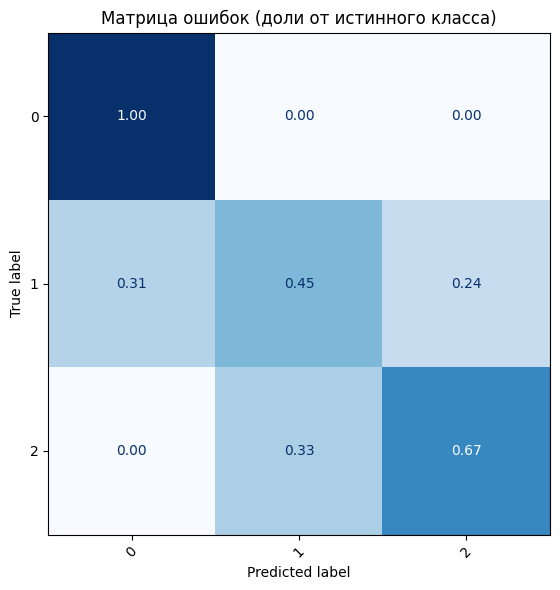

In [38]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_true).ravel()

print(f"Accuracy = {accuracy_score(y_true, y_pred):.3f}")
print(f"Macro F1 : {f1_score(y_true, y_pred, average='macro'):.3f}\n")
print(classification_report(y_true, y_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Матрица ошибок (доли от истинного класса)")
plt.tight_layout()
plt.show()